# Figure 8: recovery of the spot filling factor through the VAE

Section 4.6, `fig:vae_sff_recovery`. The conditional distribution of
the recovered spot filling factor given the true value, over every
surface in the holdout, with the conditional median and the identity
marked and the marginal distribution of the true filling factor above.

The map is normalised down each column, so a column reads as
P(recovered | true) rather than as a count: the marginal above is
strongly peaked, and a raw-count map would say more about how many
surfaces sit at each true filling factor than about how well each one
is recovered.

Both filling factors are the area-weighted fraction of the whole
sphere below the 0.9 intensity threshold, the truth on the rendered
input and the recovery on the rendered decoder-mean reconstruction.
The pass is cached, so re-running this notebook is immediate.

## Imports

In [1]:
from _setup import *

from starspot_sbi.pipeline import decode_ceiling_coeffs

## Setup

The whole holdout, the chunk size the pass works in, the binning of
the map and of the conditional median, and the filling factor where
Section 4.6 splits its two claims.

In [2]:
DEVICE = 'cuda'
CHUNK = 2000               # surfaces held in memory at once
MAP_BINS = 30              # cells across each axis of the conditional map
MARG_BINS = 30             # bins in the marginal histogram on top
N_BINS = 60                # quantile bins in the true filling factor
SFF_SPLIT = 0.05           # where Section 4.6 splits its two claims
CACHE = os.path.join(CACHES, 'fig08_sff_pairs.npz')

## Selecting the sample

Every surface in the holdout index.

In [3]:
idx = load_meta().index.values
print(f'{len(idx):,} holdout surfaces, the whole set')

100,000 holdout surfaces, the whole set


## Inference

Reconstructs every surface at the encoder mean and measures both
filling factors, one chunk in memory at a time: the holdout is 100,000
surfaces and the renders would not fit otherwise.

In [4]:
def score_all():
    """True and recovered filling factor for the whole holdout."""
    vae, stats = load_autoencoder(device=DEVICE)
    w_full = metrics.weights(0.0, *GRID, kind='full')
    true = np.empty(len(idx))
    recd = np.empty(len(idx))
    for a in range(0, len(idx), CHUNK):
        b = min(a + CHUNK, len(idx))
        coeffs = np.stack([np.load(os.path.join(HOLDOUT, 'surfaces',
                                                f'surface_{i:07d}.npy'))
                           for i in idx[a:b]])
        truth_real = np.stack([coeffs_to_real(c) for c in coeffs])
        rec = decode_ceiling_coeffs(coeffs, vae, stats, device=DEVICE)
        timgs = render_draws(truth_real, device=DEVICE)
        rimgs = render_draws(rec, device=DEVICE)
        true[a:b] = [metrics.wmean(metrics.spot_mask(timgs[k]), w_full)
                     for k in range(b - a)]
        recd[a:b] = [metrics.wmean(metrics.spot_mask(rimgs[k]), w_full)
                     for k in range(b - a)]
        print(f'  {b:,} / {len(idx):,}', flush=True)
    return dict(idx=idx, sff_true=true, sff_rec=recd)


os.makedirs(CACHES, exist_ok=True)
z = np.load(CACHE) if os.path.exists(CACHE) else None
# the guard checks the scored population, not just that a file is there, so a
# different holdout or sample size recomputes instead of being silently reused
if z is not None and z['sff_true'].size == len(idx) and np.array_equal(
        z['idx'], idx):
    d = {k: z[k] for k in z.files}
    print(f'filling factors read from {os.path.relpath(CACHE, REPO)}')
else:
    d = score_all()                 # the whole holdout; tens of minutes
    np.savez(CACHE, **d)
    print(f'filling factors written to {os.path.relpath(CACHE, REPO)}')

sff_true, sff_rec = d['sff_true'], d['sff_rec']
print(f'{sff_true.size:,} surfaces, true sff up to {sff_true.max():.4f}')

/home/conaire/miniconda3/envs/paper2_gpu/lib/python3.12/site-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


  2,000 / 100,000
  4,000 / 100,000
  6,000 / 100,000
  8,000 / 100,000
  10,000 / 100,000
  12,000 / 100,000
  14,000 / 100,000
  16,000 / 100,000
  18,000 / 100,000
  20,000 / 100,000
  22,000 / 100,000
  24,000 / 100,000
  26,000 / 100,000
  28,000 / 100,000
  30,000 / 100,000
  32,000 / 100,000
  34,000 / 100,000
  36,000 / 100,000
  38,000 / 100,000
  40,000 / 100,000
  42,000 / 100,000
  44,000 / 100,000
  46,000 / 100,000
  48,000 / 100,000
  50,000 / 100,000
  52,000 / 100,000
  54,000 / 100,000
  56,000 / 100,000
  58,000 / 100,000
  60,000 / 100,000
  62,000 / 100,000
  64,000 / 100,000
  66,000 / 100,000
  68,000 / 100,000
  70,000 / 100,000
  72,000 / 100,000
  74,000 / 100,000
  76,000 / 100,000
  78,000 / 100,000
  80,000 / 100,000
  82,000 / 100,000
  84,000 / 100,000
  86,000 / 100,000
  88,000 / 100,000
  90,000 / 100,000
  92,000 / 100,000
  94,000 / 100,000
  96,000 / 100,000
  98,000 / 100,000
  100,000 / 100,000
filling factors written to caches/fig08_sff_pairs.npz

In [5]:
# Two binnings. The map is uniform in both filling factors, so a cell is a
# cell wherever it sits; the conditional median and the numbers below use
# quantile bins in the truth, so every point of the line rests on the same
# number of surfaces. Duplicate quantile edges are collapsed: the filling
# factor ties at the low end, where many surfaces have no pixel below the
# threshold.
lim = max(sff_true.max(), sff_rec.max())
map_edges = np.linspace(0.0, lim, MAP_BINS + 1)
H, xe, ye = np.histogram2d(sff_true, sff_rec, bins=(map_edges, map_edges))
P = H / np.maximum(H.sum(axis=1, keepdims=True), 1)   # P(recovered | true)

edges = np.unique(np.quantile(sff_true, np.linspace(0, 1, N_BINS + 1)))
which = np.clip(np.searchsorted(edges, sff_true, side='right') - 1,
                0, len(edges) - 2)
counts = np.array([(which == b).sum() for b in range(len(edges) - 1)])
bins = np.where(counts > 0)[0]
counts = counts[bins]
centres = np.array([sff_true[which == b].mean() for b in bins])
med = np.array([np.median(sff_rec[which == b]) for b in bins])
sd = np.array([sff_rec[which == b].std() for b in bins])
rel = (med - centres) / np.maximum(centres, 1e-12)
fit = np.polyfit(sff_true, sff_rec, 1)
print(f'{len(centres)} quantile bins of at least {counts.min():,} '
      f'surfaces, least-squares slope {fit[0]:.3f}')

# The drawn median follows the map's own columns, so the line spans the same
# range as the map; columns holding fewer than MIN_COL surfaces are dropped,
# which trims the last near-empty cell rather than letting one surface set a
# point of the line.
MIN_COL = 50
col_n = H.sum(axis=1)
col_ok = np.where(col_n >= MIN_COL)[0]
col_x = 0.5 * (xe[:-1] + xe[1:])[col_ok]
col_which = np.clip(np.searchsorted(map_edges, sff_true, side='right') - 1,
                    0, MAP_BINS - 1)
col_med = np.array([np.median(sff_rec[col_which == b]) for b in col_ok])


60 quantile bins of at least 1,666 surfaces, least-squares slope 0.915


## Plotting

Draws the figure from the names bound above.

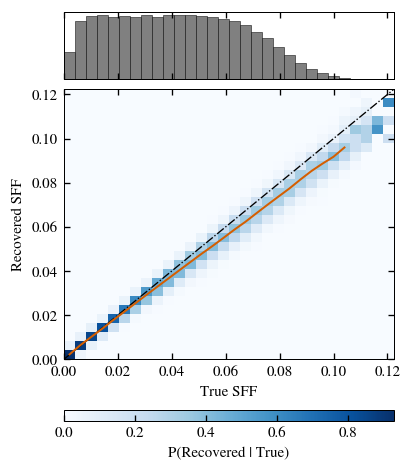

In [6]:
fig, (ax0, ax) = plt.subplots(2, 1, figsize=(COL, COL * 1.15),
                              sharex=True,
                              gridspec_kw={'height_ratios': [1, 4]})
ax0.hist(sff_true, bins=MARG_BINS, color=GRAY, edgecolor='black', lw=0.3)
ax0.set_yticks([])

m = ax.pcolormesh(xe, ye, P.T, cmap='Blues', vmin=0.0, rasterized=True)
ax.plot([0, lim], [0, lim], color='black', ls='-.', lw=0.8)
ax.plot(col_x, col_med, color=RED, lw=1.2)
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_xlabel('True SFF')
ax.set_ylabel('Recovered SFF')

# horizontal below the map, as in the draft: the colour is the conditional
# probability, and reading it against the x axis is the point of the figure
fig.colorbar(m, ax=ax, orientation='horizontal', location='bottom',
             pad=0.04, fraction=0.05, aspect=30, label='P(Recovered | True)')

## Saving and caption numbers

Writes the pdf and png, then prints the numbers the Section 4.6 text
quotes: unbiased recovery below a true filling factor of about 0.05, a
mild systematic underestimate above it, and the size of that
underestimate at the top of the range.

In [7]:
save_fig(fig, 'fig08_vae_sff_recovery')
below, above = centres < SFF_SPLIT, centres >= SFF_SPLIT
print(f'median relative bias below sff {SFF_SPLIT}: '
      f'{np.median(rel[below]) * 100:+.1f} per cent')
print(f'median relative bias above sff {SFF_SPLIT}: '
      f'{np.median(rel[above]) * 100:+.1f} per cent')
print(f'relative bias in the top bin (sff {centres[-1]:.3f}): '
      f'{rel[-1] * 100:+.1f} per cent')
print(f'conditional spread: {sd[1]:.4f} at sff {centres[1]:.3f}, '
      f'{sd[-1]:.4f} at sff {centres[-1]:.3f}')
print(f'least-squares slope {fit[0]:.3f}, intercept {fit[1]:+.5f}')

wrote notebooks/paper/figs/fig08_vae_sff_recovery.pdf, notebooks/paper/figs/fig08_vae_sff_recovery.png
median relative bias below sff 0.05: -4.0 per cent
median relative bias above sff 0.05: -7.1 per cent
relative bias in the top bin (sff 0.096): -7.9 per cent
conditional spread: 0.0009 at sff 0.004, 0.0068 at sff 0.096
least-squares slope 0.915, intercept +0.00087
